In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

from itertools import combinations
from sklearn.model_selection import ParameterGrid

from bandit import Bandit
from agents import EpsilonGreedyAgent, UCBAgent
from estimators import ConstantStepSizeEstimator, SampleAverageEstimator
from simulation import bandit_agent_run, run_simulation, run_experiment_parallel

%load_ext autoreload
%autoreload 2

# Stationary Bandits Testbed

## Set up Bandit with $q_{true} \sim \mathcal{N}(0,1)$

In [2]:
# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 1.0
drift_var = 0.0

# Agent parameters
epsilon = 0.1
c = 2.0

# Simulation parameters
T = 1000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

## Optimistic initial values vs $\epsilon$-greedy action-value method

In [7]:
%%time

# Estimator parameters
estimator = ConstantStepSizeEstimator
initial_q = 5

# Simulation parameters
T = 1000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

average_rewards = np.empty((3, T))
percent_optimal_actions = np.empty((3, T))

average_rewards[0], percent_optimal_actions[0] = run_experiment_parallel(
    R, T, k, estimator, EpsilonGreedyAgent,
    q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
    epsilon=epsilon
)
average_rewards[1], percent_optimal_actions[1] = run_experiment_parallel(
    R, T, k, estimator, EpsilonGreedyAgent,
    q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
    initial_q=initial_q,
    epsilon=0.0
)
average_rewards[2], percent_optimal_actions[2] = run_experiment_parallel(
    R, T, k, estimator, UCBAgent,
    q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
    c=c
)

CPU times: user 1.92 s, sys: 336 ms, total: 2.26 s
Wall time: 17.1 s


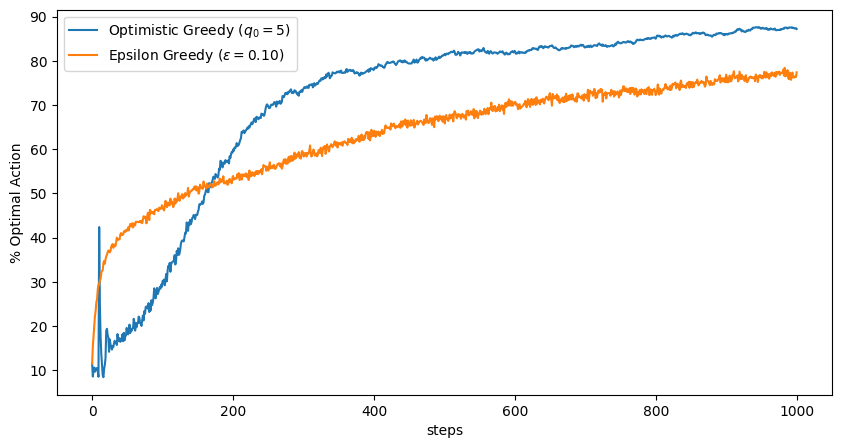

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(percent_optimal_actions[1], label="Optimistic Greedy ($q_0 = %.0f$)" % (initial_q))
plt.plot(percent_optimal_actions[0], label="Epsilon Greedy ($\\epsilon = %.02f$)" % (epsilon))
plt.xlabel("steps")
plt.ylabel("% Optimal Action")
plt.legend()

plt.savefig("../images/figure_2_3.png", bbox_inches="tight")

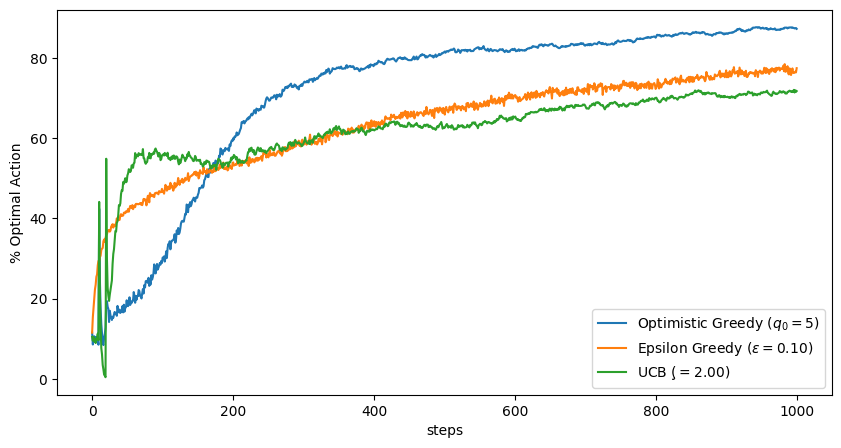

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(percent_optimal_actions[1], label="Optimistic Greedy ($q_0 = %.0f$)" % (initial_q))
plt.plot(percent_optimal_actions[0], label="Epsilon Greedy ($\\epsilon = %.02f$)" % (epsilon))
plt.plot(percent_optimal_actions[2], label="UCB ($\\c = %.02f$)" % (c))
plt.xlabel("steps")
plt.ylabel("% Optimal Action")
plt.legend()

plt.savefig("../images/figure_2_3_ucb.png", bbox_inches="tight")

## UCB

In [20]:
%%time

# Estimator parameters
estimator = SampleAverageEstimator

# Simulation parameters
T = 1000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

average_rewards = np.empty((2, T))
percent_optimal_actions = np.empty((2, T))

average_rewards[0], percent_optimal_actions[0] = run_experiment_parallel(
    R, T, k, estimator, EpsilonGreedyAgent,
    q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
    epsilon=epsilon
)
average_rewards[1], percent_optimal_actions[1] = run_experiment_parallel(
    R, T, k, estimator, UCBAgent,
    q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
    c=c
)

CPU times: user 1.19 s, sys: 163 ms, total: 1.36 s
Wall time: 10.9 s


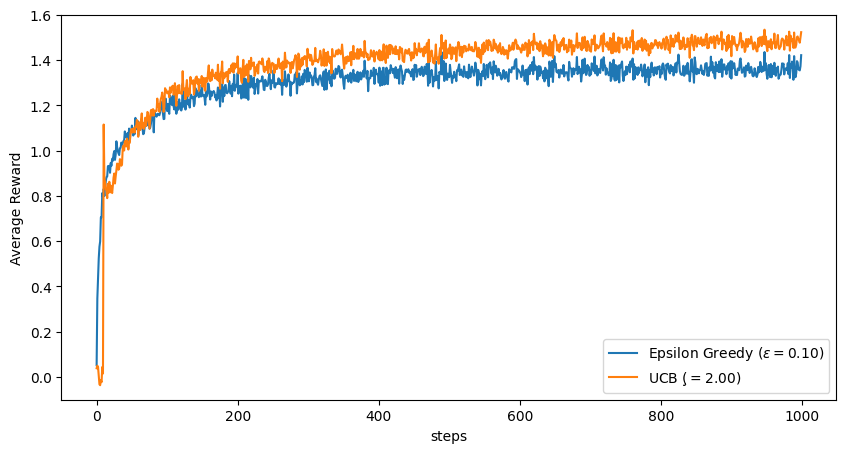

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(average_rewards[0], label="Epsilon Greedy ($\\epsilon = %.02f$)" % (epsilon))
plt.plot(average_rewards[1], label="UCB ($\\c = %.02f$)" % (c))
plt.ylim(-0.1, 1.6)
plt.xlabel("steps")
plt.ylabel("Average Reward")
plt.legend()

plt.savefig("../images/figure_2_4.png", bbox_inches="tight")

# Non-stationary Bandits Testbed

### Set up Bandit with drifting q_true values

In [13]:
# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0  # or should this be 1.0?
drift_var = 0.01

# Agent parameters
epsilon = 0.1

# Agent and test parameters
T = 10000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

Initial optimal reward:	 0.0
Final optimal reward:	 0.98735


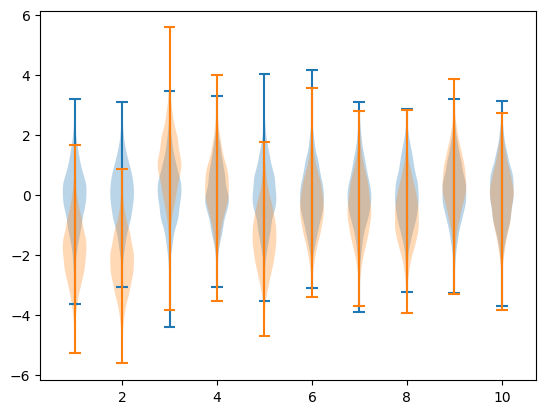

In [14]:
# Visualize an example
bandit = Bandit(k, q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var)
q_true_values = np.zeros((k, T))

rewards_start = [bandit.sample(a, R) for a in range(0, k)]
print(f"Initial optimal reward:\t {round(bandit._q_true.max().item(), 5)}")

# Take a number of time steps, at each of which the q_true valus take independent random walks
for i in range(T):
    q_true_values[:, i] = bandit._q_true
    bandit.reward(0)
rewards_end = [bandit.sample(a, R) for a in range(0, k)]
print(f"Final optimal reward:\t {round(bandit._q_true.max().item(), 5)}")

plt.violinplot(rewards_start)
plt.violinplot(rewards_end);

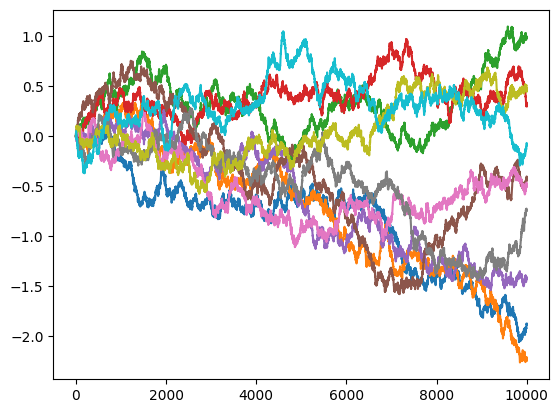

In [15]:
plt.plot(q_true_values.T);

### Compare sample-average with constant step-size action-value methods

Average reward for sample average:  0.7037529671728684
Average reward for constant step size:  0.8696984433881544
CPU times: user 10.2 s, sys: 3.94 s, total: 14.1 s
Wall time: 3min 46s


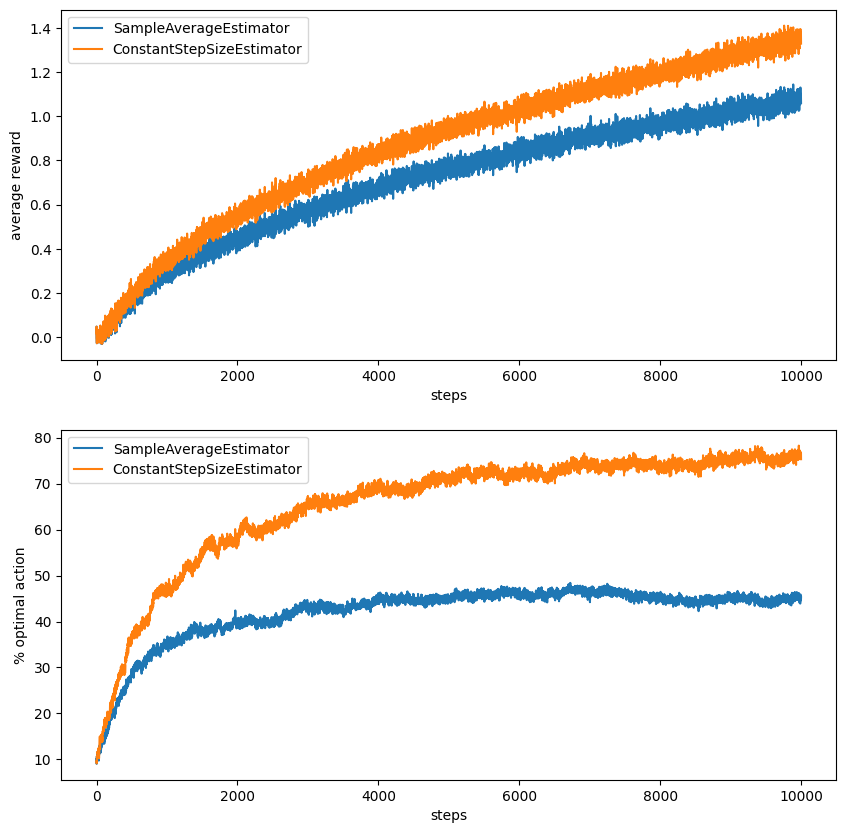

In [16]:
%%time

# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0
drift_var = 0.01

# Agent parameters
epsilon = 0.1
estimators = [SampleAverageEstimator, ConstantStepSizeEstimator]

# Simulation parameters
T = 10000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

average_rewards = np.empty((len(estimators), T))
percent_optimal_actions = np.empty((len(estimators), T))

for i, estimator in enumerate(estimators):
    average_rewards[i], percent_optimal_actions[i] = run_experiment_parallel(
        R, epsilon, T, k, estimator, 
        q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var
    )


print("Average reward for sample average: ", np.mean(average_rewards[0]))
print("Average reward for constant step size: ", np.mean(average_rewards[1]))


plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
for i, estimator in enumerate(estimators):
    plt.plot(average_rewards[i], label=estimator.__name__)
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, estimator in enumerate(estimators):
    plt.plot(percent_optimal_actions[i], label=estimator.__name__)
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()

plt.savefig('../images/figure_2_2_ns.png', bbox_inches="tight")